## <b>Intelligence Artificielle pour la Mobilité Autonome -> Notebook d'exercices n°2</b>

L'objectif ici est d'appliquer <b>différents classifieurs sur un même dataset</b>.  
On utilisera pour cela le <b>dataset MNIST</b>.  
Cela permettra de <b>comparer les performances</b> de ces différents classifieurs.  
  
Pour chacun des algorithmes, il s'agit de rechercher la <b>meilleure précision</b> en jouant sur son paramétrage, et de calculer les temps de traitement :
- <b>durée d'adaptation</b> du classifieur (fonction "fit")
- <b>durée de la prédiction</b> (=inférence) sur l'ensemble de test (fonction "predict")  

NB :
- On pourra automatiser les tests en utilisant des <b>boucles</b> sur les paramètres à tester, ceux-ci étant définis par des <b>listes</b>.  
- Connaissant la taille de l'ensemble de test de MNIST (10000 images par défaut), le temps de la prédiction sur cet ensemble donne une bonne idée du temps de traitement d'une seule image (pour l'utilisation en mode réel).
- En fonction du classifieur utilisé, il faudra peut-être parfois n'utiliser qu'une partie du dataset, si le temps de traitement est trop long (mais cela risque de réduire sa précision).

Une fois tous les algorithmes testé sur les données MNIST, un tableau récapitulatif devra donner un <b>aperçu global de leur performance</b>, à la fois en termes de <b>précision</b> que de <b>durée de l'inférence</b>.

### <b>Exercice 2.1 : KPPV</b>

Tester l'algorithme sur les données MNIST avec différentes valeurs de K pour rechercher la <b>valeur optimale</b>.   
Utiliser pour cela <b>une boucle</b> faisant varier la valeur de K de façon automatique, avec les <b>éléments de programmation</b> utilisés dans le notebook de référence.   
Visualiser <b>graphiquement</b> la précision en fonction de la valeur de K.  
Déterminer la valeur de K permettant d'obtenir la <b>meilleure précision</b> (accuracy) avec les données MNIST.

In [11]:
from sklearn.neighbors import KNeighborsClassifier
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

mnist = pd.read_csv('/home/jovyan/iadatasets/MNIST/mnist_train.csv')

X = mnist.values[:, 1:]      
y = mnist.values[:, 0]        


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.5, random_state = 0)


classifier = KNeighborsClassifier(n_neighbors = 3)

classifier.fit(X_train, y_train)

probs_y = classifier.predict_proba(X_test)   #probabilités pour chaque classe
print("Probabilités d'appartenance aux 3 classes pour chaque donnée de test :")
print(np.round(probs_y, 2))     #arrondir à 2 décimales

         

Probabilités d'appartenance aux 3 classes pour chaque donnée de test :
[[1.   0.   0.   ... 0.   0.   0.  ]
 [0.   0.   0.   ... 0.   0.   0.  ]
 [0.   0.   0.   ... 0.   0.   0.  ]
 ...
 [0.   0.   0.   ... 0.   0.   0.  ]
 [0.   1.   0.   ... 0.   0.   0.  ]
 [0.   0.   0.   ... 0.33 0.   0.67]]


In [12]:
from sklearn import metrics

y_pred = classifier.predict(X_test)      #prédiction (classes estimées)
score = metrics.accuracy_score(y_test, y_pred)  #fonction équivalente

print("taux de classification correcte : ")
print(round(score, 3))    

taux de classification correcte : 
0.967


La précision obtenue pour k=3 voisins est de 96,7%.

In [24]:
from sklearn.neighbors import KNeighborsClassifier
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

mnist = pd.read_csv('/home/jovyan/iadatasets/MNIST/mnist_test.csv')

X = mnist.values[:, 1:]      
y = mnist.values[:, 0]        


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.5, random_state = 0)

print("Probabilités d'appartenance aux k classes pour chaque donnée de test :")

for n_neighbors in range(1,20):
    classifier = KNeighborsClassifier(n_neighbors)
    classifier.fit(X_train, y_train)
    probs_y = classifier.predict_proba(X_test)   #probabilités pour chaque classe
    print(np.round(probs_y, 2))     #arrondir à 2 décimales
    y_pred = classifier.predict(X_test)      #prédiction (classes estimées)
    score = metrics.accuracy_score(y_test, y_pred)  #fonction équivalente
    print("taux de classification correcte : ")
    print(round(score, 3))  
    print("K = {}".format(n_neighbors))

Probabilités d'appartenance aux k classes pour chaque donnée de test :
[[0. 0. 0. ... 1. 0. 0.]
 [0. 0. 0. ... 0. 1. 0.]
 [0. 0. 0. ... 1. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]]
taux de classification correcte : 
0.942
K = 1
[[0.  0.  0.  ... 1.  0.  0. ]
 [0.  0.  0.  ... 0.  1.  0. ]
 [0.  0.  0.  ... 1.  0.  0. ]
 ...
 [0.  0.  0.  ... 0.5 0.  0.5]
 [0.  0.  0.  ... 0.  0.  0. ]
 [0.  1.  0.  ... 0.  0.  0. ]]
taux de classification correcte : 
0.931
K = 2
[[0.   0.   0.   ... 1.   0.   0.  ]
 [0.   0.   0.   ... 0.   1.   0.  ]
 [0.   0.   0.   ... 1.   0.   0.  ]
 ...
 [0.   0.   0.   ... 0.67 0.   0.33]
 [0.   0.   0.   ... 0.   0.   0.  ]
 [0.   1.   0.   ... 0.   0.   0.  ]]
taux de classification correcte : 
0.944
K = 3
[[0.   0.   0.   ... 1.   0.   0.  ]
 [0.   0.   0.   ... 0.   0.75 0.  ]
 [0.   0.   0.   ... 1.   0.   0.  ]
 ...
 [0.   0.   0.   ... 0.5  0.   0.25]
 [0.   0.   0.   ... 0.   0.   0.  ]
 [0.   1.   0.   ... 0

In [ ]:
GRAPHIQUE :
    

Les scores :
[0.942]
[0.942, 0.9308]
[0.942, 0.9308, 0.944]
[0.942, 0.9308, 0.944, 0.9406]
[0.942, 0.9308, 0.944, 0.9406, 0.9432]
[0.942, 0.9308, 0.944, 0.9406, 0.9432, 0.9392]
[0.942, 0.9308, 0.944, 0.9406, 0.9432, 0.9392, 0.9394]
[0.942, 0.9308, 0.944, 0.9406, 0.9432, 0.9392, 0.9394, 0.9366]
[0.942, 0.9308, 0.944, 0.9406, 0.9432, 0.9392, 0.9394, 0.9366, 0.937]
[0.942, 0.9308, 0.944, 0.9406, 0.9432, 0.9392, 0.9394, 0.9366, 0.937, 0.9344]
[0.942, 0.9308, 0.944, 0.9406, 0.9432, 0.9392, 0.9394, 0.9366, 0.937, 0.9344, 0.9338]
[0.942, 0.9308, 0.944, 0.9406, 0.9432, 0.9392, 0.9394, 0.9366, 0.937, 0.9344, 0.9338, 0.931]
[0.942, 0.9308, 0.944, 0.9406, 0.9432, 0.9392, 0.9394, 0.9366, 0.937, 0.9344, 0.9338, 0.931, 0.9296]
[0.942, 0.9308, 0.944, 0.9406, 0.9432, 0.9392, 0.9394, 0.9366, 0.937, 0.9344, 0.9338, 0.931, 0.9296, 0.9282]
[0.942, 0.9308, 0.944, 0.9406, 0.9432, 0.9392, 0.9394, 0.9366, 0.937, 0.9344, 0.9338, 0.931, 0.9296, 0.9282, 0.929]
[0.942, 0.9308, 0.944, 0.9406, 0.9432, 0.9392, 0.939

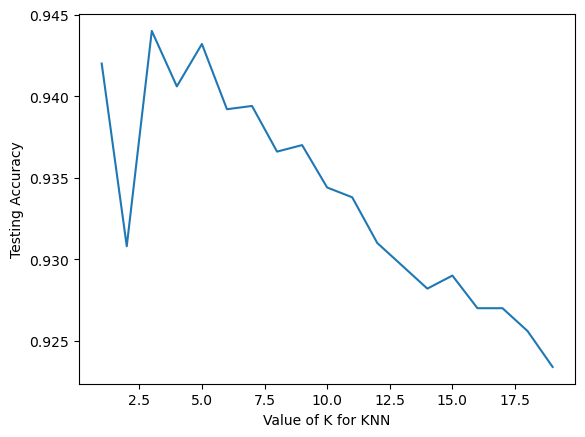

In [28]:
from sklearn.neighbors import KNeighborsClassifier
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

mnist = pd.read_csv('/home/jovyan/iadatasets/MNIST/mnist_test.csv')

X = mnist.values[:, 1:]      
y = mnist.values[:, 0]        


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.5, random_state = 0)

print("Les scores :")

k_range = range(1,20)
scores = []
for n_neighbors in range(1,20):
    classifier = KNeighborsClassifier(n_neighbors)
    classifier.fit(X_train, y_train)
    probs_y = classifier.predict_proba(X_test)   #probabilités pour chaque classe
    y_pred = classifier.predict(X_test)      #prédiction (classes estimées)
    score = metrics.accuracy_score(y_test, y_pred)  #fonction équivalente
    scores.append(score)
    print(scores)
    
plt.plot(k_range, scores)
plt.xlabel('Value of K for KNN')
plt.ylabel('Testing Accuracy')
plt.show()

### <b>Exercice 2.2 : Arbres de décision</b>

Appliquer le classifieur Random Forest sur les données MNIST, d'abord avec les <b>paramètres par défaut</b>.  
Essayer de mettre en évidence le phénomène d'<b>apprentissage par coeur</b>.

##### <b>Commentaires :</b>

bla bla bla

Faire varier le paramètre de <b>profondeur maximale</b> de l'arbre dans une boucle.  
Visualiser <b>graphiquement</b> la précision en fonction de la valeur de K.  

##### <b>Commentaires :</b>

bla bla bla

### <b>Exercice 2.3 : Random Forest</b>

Appliquer le classifieur Random Forest sur les données MNIST, avec les <b>paramètres par défaut</b>.  

##### <b>Commentaires :</b>

bla bla bla

Faire varier le paramètre de <b>nombre d'arbres</b> dans une boucle.   
Visualiser graphiquement les résultats et les <b>interpréter</b>.

##### <b>Commentaires :</b>

bla bla bla

Faire varier le paramètre de <b>nombre de features utilisés par chaque arbre</b> dans une boucle.   
Visualiser graphiquement les résultats et les <b>interpréter</b>.

##### <b>Commentaires :</b>

bla bla bla